# 2 — Fresh PCA and LDA baselines
Each run independently rebuilds sources, targets, splits and assemblies. PCA is unsupervised pooled-bin full SVD with rank≥8. LDA is explicitly a supervised classifier, not a dimension-matched embedding. Full/reduced interventions refit all stages.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from neuro.notebook_inputs import configuration_from_environment, inspect_inputs, load_inputs, effective_pair_map
from neuro.pseudopopulation import sample_plan, materialize, support
from neuro.notebook_artifacts import ArtifactStore, FitAccounting, target_heads, write_private_json, verify_artifacts, runtime_identity, validate_kernel_identity
from neuro.notebook_support import workspace, usage_summary, source_budget, checked_assemblies, compact_metrics, plot_confusions

configuration = configuration_from_environment()
settings = configuration['execution']
output = workspace()
def private_warning(message, category, filename, lineno, file=None, line=None):
    # Preserve full provenance privately; do not render host paths in shared figures/output.
    warning_path = output / 'warnings-private.jsonl'
    with warning_path.open('a') as handle:
        handle.write(json.dumps({'message': str(message), 'category': category.__name__, 'filename': filename, 'lineno': lineno}) + '\n')
    warning_path.chmod(0o600)
    print(category.__name__ + ': ' + str(message), file=sys.stderr)
warnings.showwarning = private_warning
store = ArtifactStore(output / 'artifacts')
store.save('configuration', configuration)
store.save('kernel_runtime_before_inputs', validate_kernel_identity(configuration))
print('Input mode:', configuration['mode'], '| exploratory computational assay; no biological IID inference')

Input mode: invented | exploratory computational assay; no biological IID inference


## Explicit metadata and target boundary
Authenticate only supplied files, regenerate eligibility/assignments, freeze the contributor embargo and complete-support panel before neural interpretation. The public default is invented data. Missing supplied inputs fail; no demo or historical-result fallback.

In [2]:
inspection = inspect_inputs(configuration)  # Metadata/hash step only for supplied inputs.
store.save('metadata_selection', inspection)  # Protected provenance; never displayed.
print(json.dumps(inspection.audit, sort_keys=True))
assert inspection.audit['contributor_overlap'] == 0
assert inspection.audit['selected_train'] > 0 and inspection.audit['selected_development'] > 0

{"access": "invented fixture; no biological input files", "contributor_overlap": 0, "eligible": 216, "embargo_removed_train": 0, "exclusion_counts": {}, "original_development": 72, "original_sessions": 3, "original_train": 144, "original_units": 9, "selected_development": 72, "selected_sessions": 3, "selected_train": 144, "selected_units": 9, "surviving_train": 144}


In [3]:
data, neural_audit = load_inputs(inspection)  # Supplied neural path remains explicitly review-gated.
store.save('source_data', data)
store.save('neural_audit', neural_audit)
print(json.dumps(neural_audit, sort_keys=True))
assert np.isfinite(data.values[data.observed]).all()
assert np.isnan(data.values[~data.observed]).all()
assert not data.dependency_audit()['overlapping_contributor_ids']
print('Source × unit × bin shape:', data.values.shape, '| units:', data.value_unit, '| clock units:', data.time_unit)

{"access": "fresh invented count generation", "full_exposure": true, "observed_values": 2592, "unavailable_values": 5184}
Source × unit × bin shape: (216, 9, 4) | units: count | clock units: s


## Freeze development lineage before interventions
Observed computational seeds 0/1 share development seed 0. Reduced training pools use a nested floor-half subset with fixed subset seed. No singleton fallback.

In [4]:
from neuro.pca_lda import fit_standardizer, raw_features, fit_pca, fit_lda
from neuro.notebook_support import fit_logistic
observed = effective_pair_map(data, permutation_seed=None)
dev_plan = sample_plan(data, split_id='development', rows_per_condition=settings['development_rows_per_condition'], seed=0, effective_conditions=observed)
reference_development = materialize(data, dev_plan)
store.save('fixed_development', reference_development)
accounting = FitAccounting().start()
results = []

## Visible refit/readout grid
Raw features retain unit-major ordering; PCA features are time-major. Both use training-only pooled-bin normalization. Readouts separately scale training features. Three explicit heads are pair/start/goal; logistic convergence and finiteness are mandatory.

observed_seed0_full source accounting: {"eligible_sources": 144, "repeated_sources": 41, "reuse_histogram": {"0": 49, "1": 54, "2": 34, "3": 6, "4": 1}, "unused_sources": 49, "used_sources": 95}
observed_seed0_full PCA explained variance: [0.1858000010251999, 0.1695999950170517, 0.16249999403953552, 0.11069999635219574, 0.09040000289678574, 0.0771000012755394, 0.0722000002861023, 0.06719999760389328]


[{"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": "pair", "log_loss": 1.4472202746403922, "macro_F1": 0.5244708994708994, "name": "observed_seed0_full_raw_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.4375}, {"accuracy": 0.5833333333333334, "development_BA": 0.5833333333333334, "head": "start", "log_loss": 0.934599828772277, "macro_F1": 0.5777777777777778, "name": "observed_seed0_full_raw_start", "train_BA": 0.9583333333333334, "train_development_gap": 0.375}, {"accuracy": 0.5833333333333334, "development_BA": 0.5833333333333334, "head": "goal", "log_loss": 0.9382765802010958, "macro_F1": 0.5874183006535948, "name": "observed_seed0_full_raw_goal", "train_BA": 0.9166666666666666, "train_development_gap": 0.33333333333333326}, {"accuracy": 0.4583333333333333, "development_BA": 0.4583333333333333, "head": "pair", "log_loss": 1.5421393198985764, "macro_F1": 0.45171957671957674, "name": "observed_seed0_full_pca_pair", "train_BA": 0.958333333

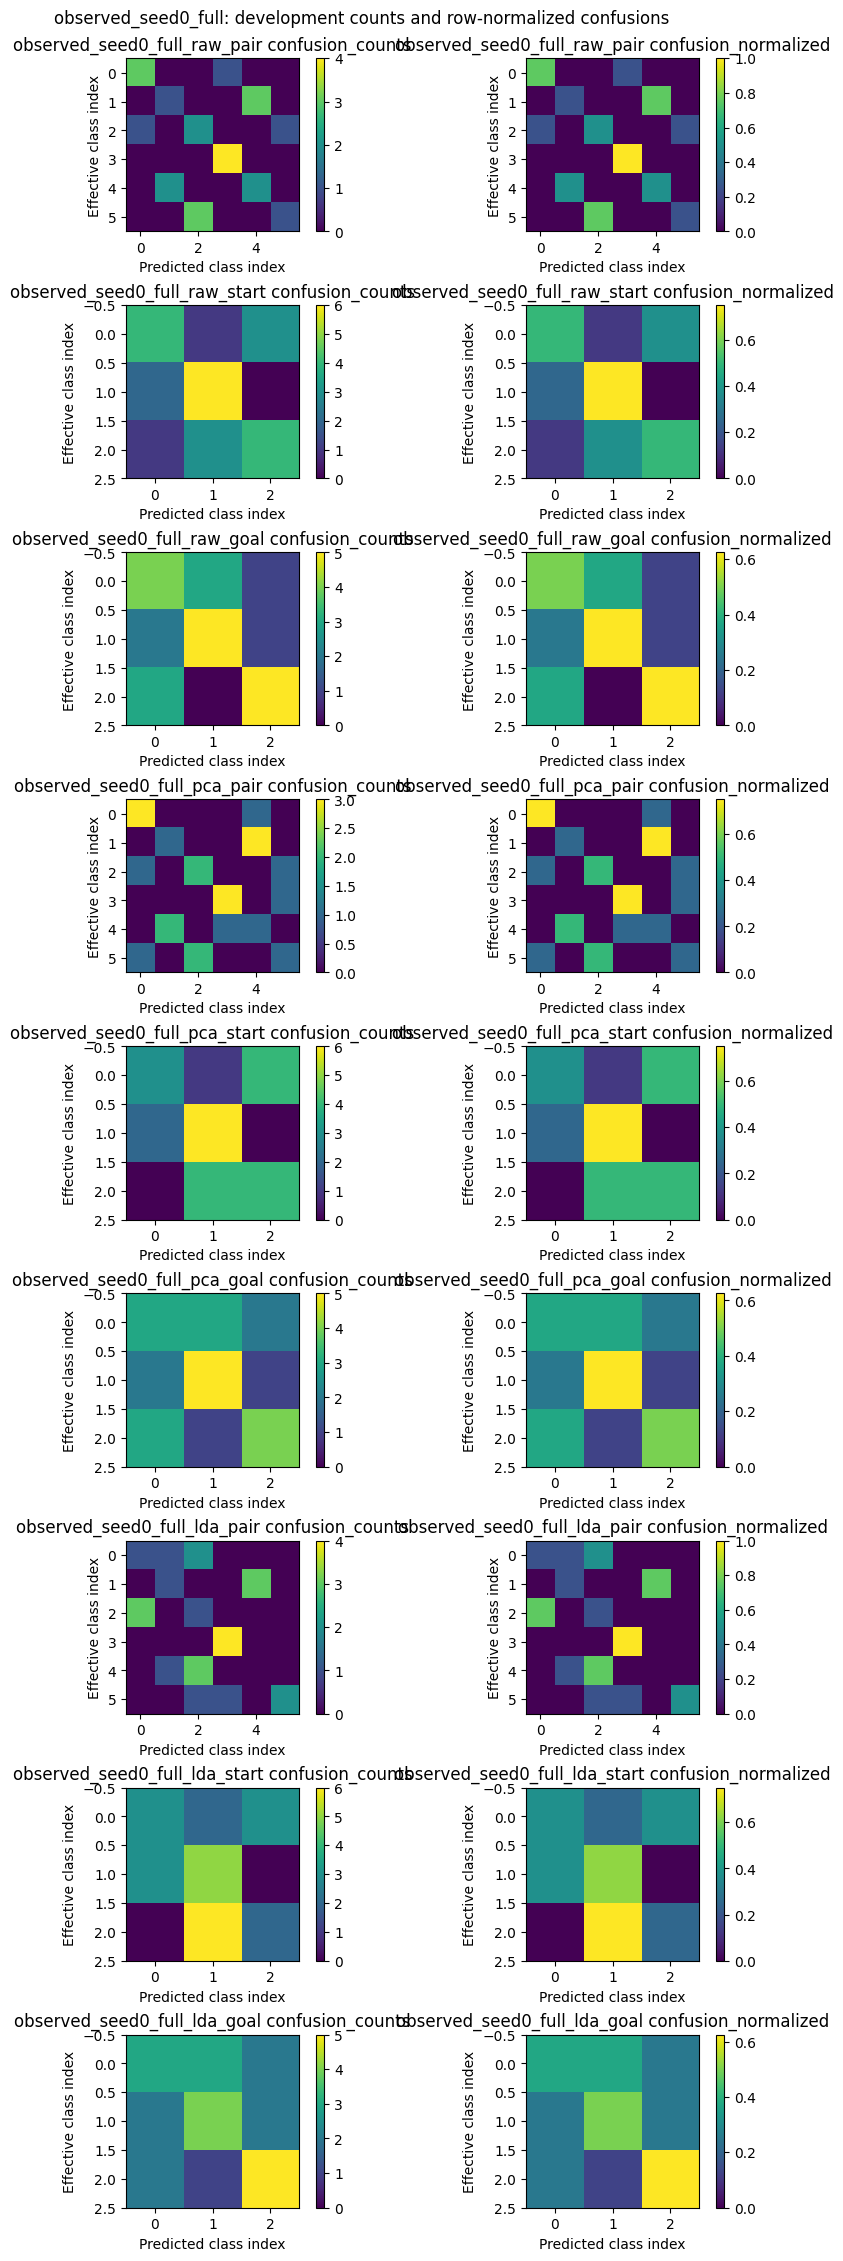

observed_seed0_reduced source accounting: {"eligible_sources": 72, "repeated_sources": 45, "reuse_histogram": {"0": 5, "1": 22, "2": 19, "3": 21, "4": 4, "5": 1}, "unused_sources": 5, "used_sources": 67}
observed_seed0_reduced PCA explained variance: [0.19949999451637268, 0.1784999966621399, 0.164000004529953, 0.10050000250339508, 0.08860000222921371, 0.08410000056028366, 0.07109999656677246, 0.05810000002384186]
[{"accuracy": 0.6666666666666666, "development_BA": 0.6666666666666666, "head": "pair", "log_loss": 1.4307729482725293, "macro_F1": 0.6549422799422799, "name": "observed_seed0_reduced_raw_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.3125}, {"accuracy": 0.5, "development_BA": 0.5, "head": "start", "log_loss": 0.9870779302306308, "macro_F1": 0.49807273336685104, "name": "observed_seed0_reduced_raw_start", "train_BA": 0.9166666666666666, "train_development_gap": 0.41666666666666663}, {"accuracy": 0.5, "development_BA": 0.5, "head": "goal", "log_loss": 0.94329

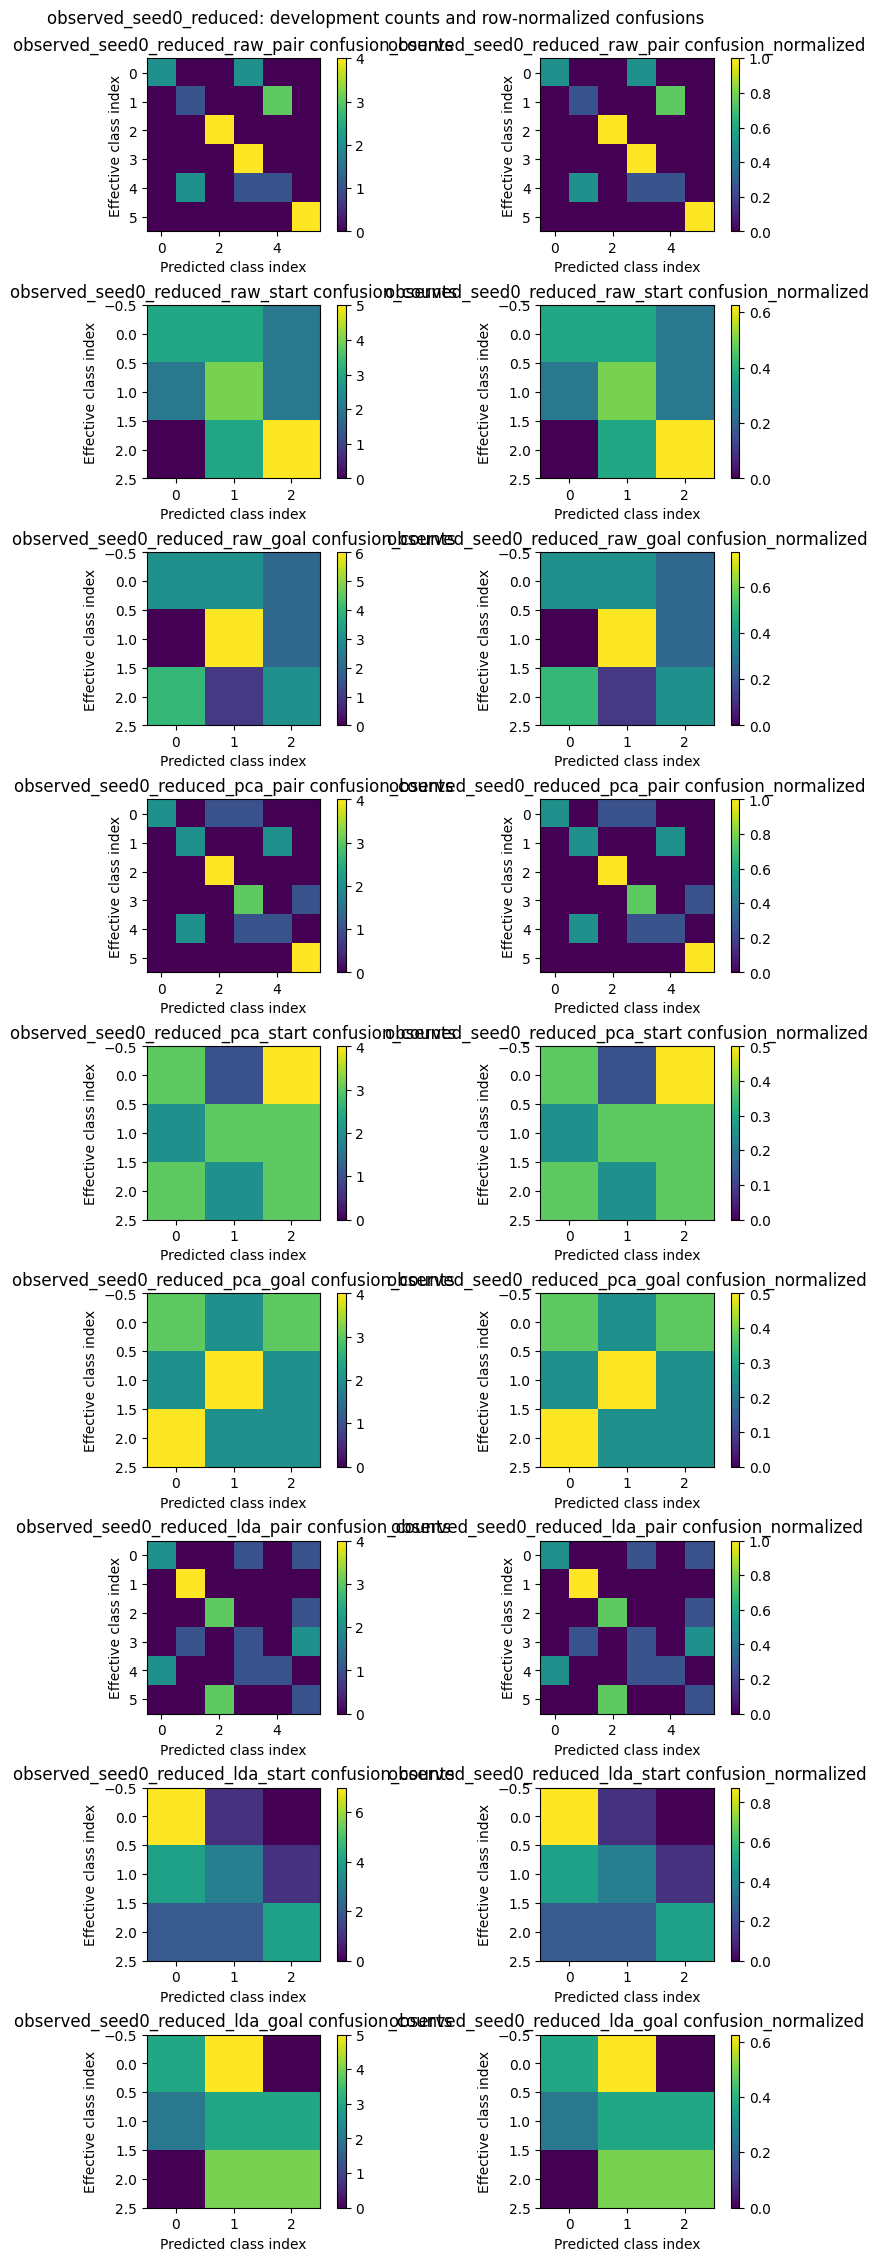

observed_seed1_full source accounting: {"eligible_sources": 144, "repeated_sources": 41, "reuse_histogram": {"0": 51, "1": 52, "2": 33, "3": 6, "4": 2}, "unused_sources": 51, "used_sources": 93}
observed_seed1_full PCA explained variance: [0.20520000159740448, 0.17630000412464142, 0.15160000324249268, 0.0989999994635582, 0.09229999780654907, 0.07900000363588333, 0.07190000265836716, 0.06589999794960022]
[{"accuracy": 0.6666666666666666, "development_BA": 0.6666666666666666, "head": "pair", "log_loss": 1.4675189499421784, "macro_F1": 0.6438672438672438, "name": "observed_seed1_full_raw_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.3125}, {"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": "start", "log_loss": 0.9640804543020621, "macro_F1": 0.5376180836707153, "name": "observed_seed1_full_raw_start", "train_BA": 0.9791666666666666, "train_development_gap": 0.4375}, {"accuracy": 0.4583333333333333, "development_BA": 0.4583333333333333, "head

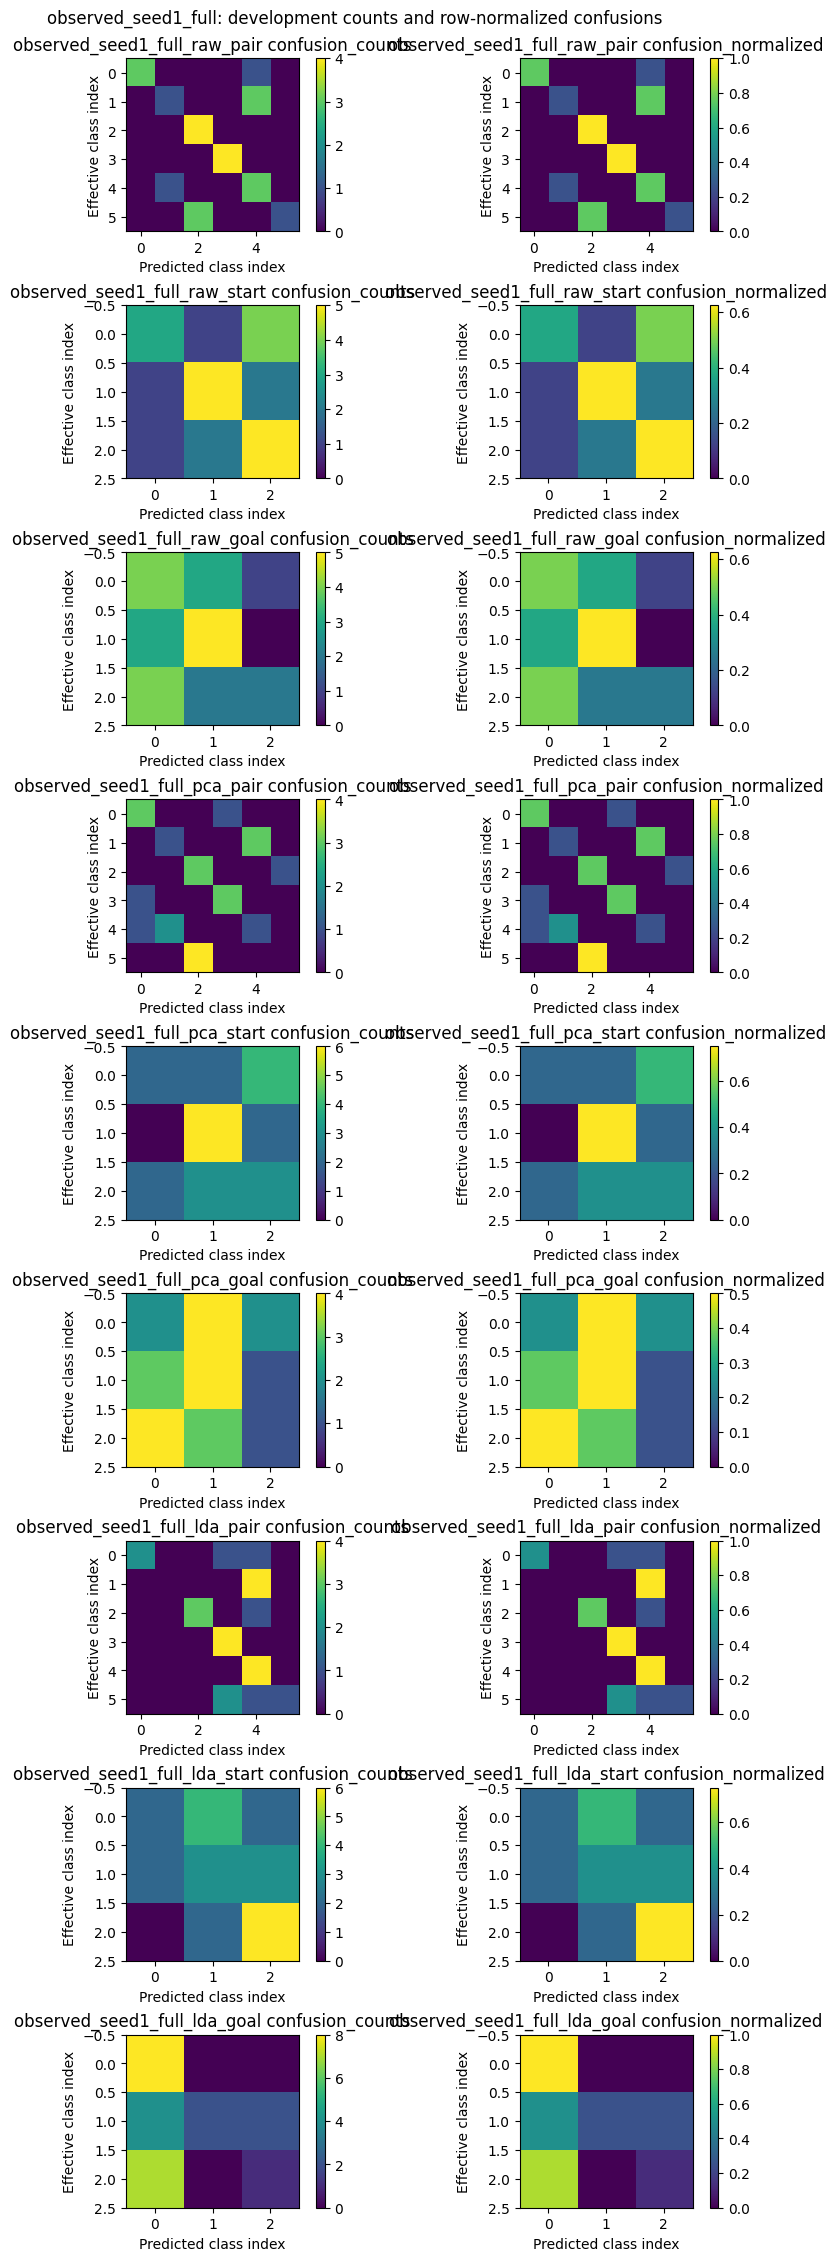

observed_seed1_reduced source accounting: {"eligible_sources": 72, "repeated_sources": 48, "reuse_histogram": {"0": 11, "1": 13, "2": 24, "3": 13, "4": 11}, "unused_sources": 11, "used_sources": 61}
observed_seed1_reduced PCA explained variance: [0.22419999539852142, 0.18889999389648438, 0.1370999962091446, 0.10930000245571136, 0.08169999718666077, 0.07639999687671661, 0.06960000097751617, 0.06310000270605087]
[{"accuracy": 0.5833333333333334, "development_BA": 0.5833333333333334, "head": "pair", "log_loss": 1.437835607332568, "macro_F1": 0.5053391053391053, "name": "observed_seed1_reduced_raw_pair", "train_BA": 1.0, "train_development_gap": 0.41666666666666663}, {"accuracy": 0.625, "development_BA": 0.625, "head": "start", "log_loss": 0.9939539517148978, "macro_F1": 0.6145667198298777, "name": "observed_seed1_reduced_raw_start", "train_BA": 0.9791666666666666, "train_development_gap": 0.35416666666666663}, {"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": 

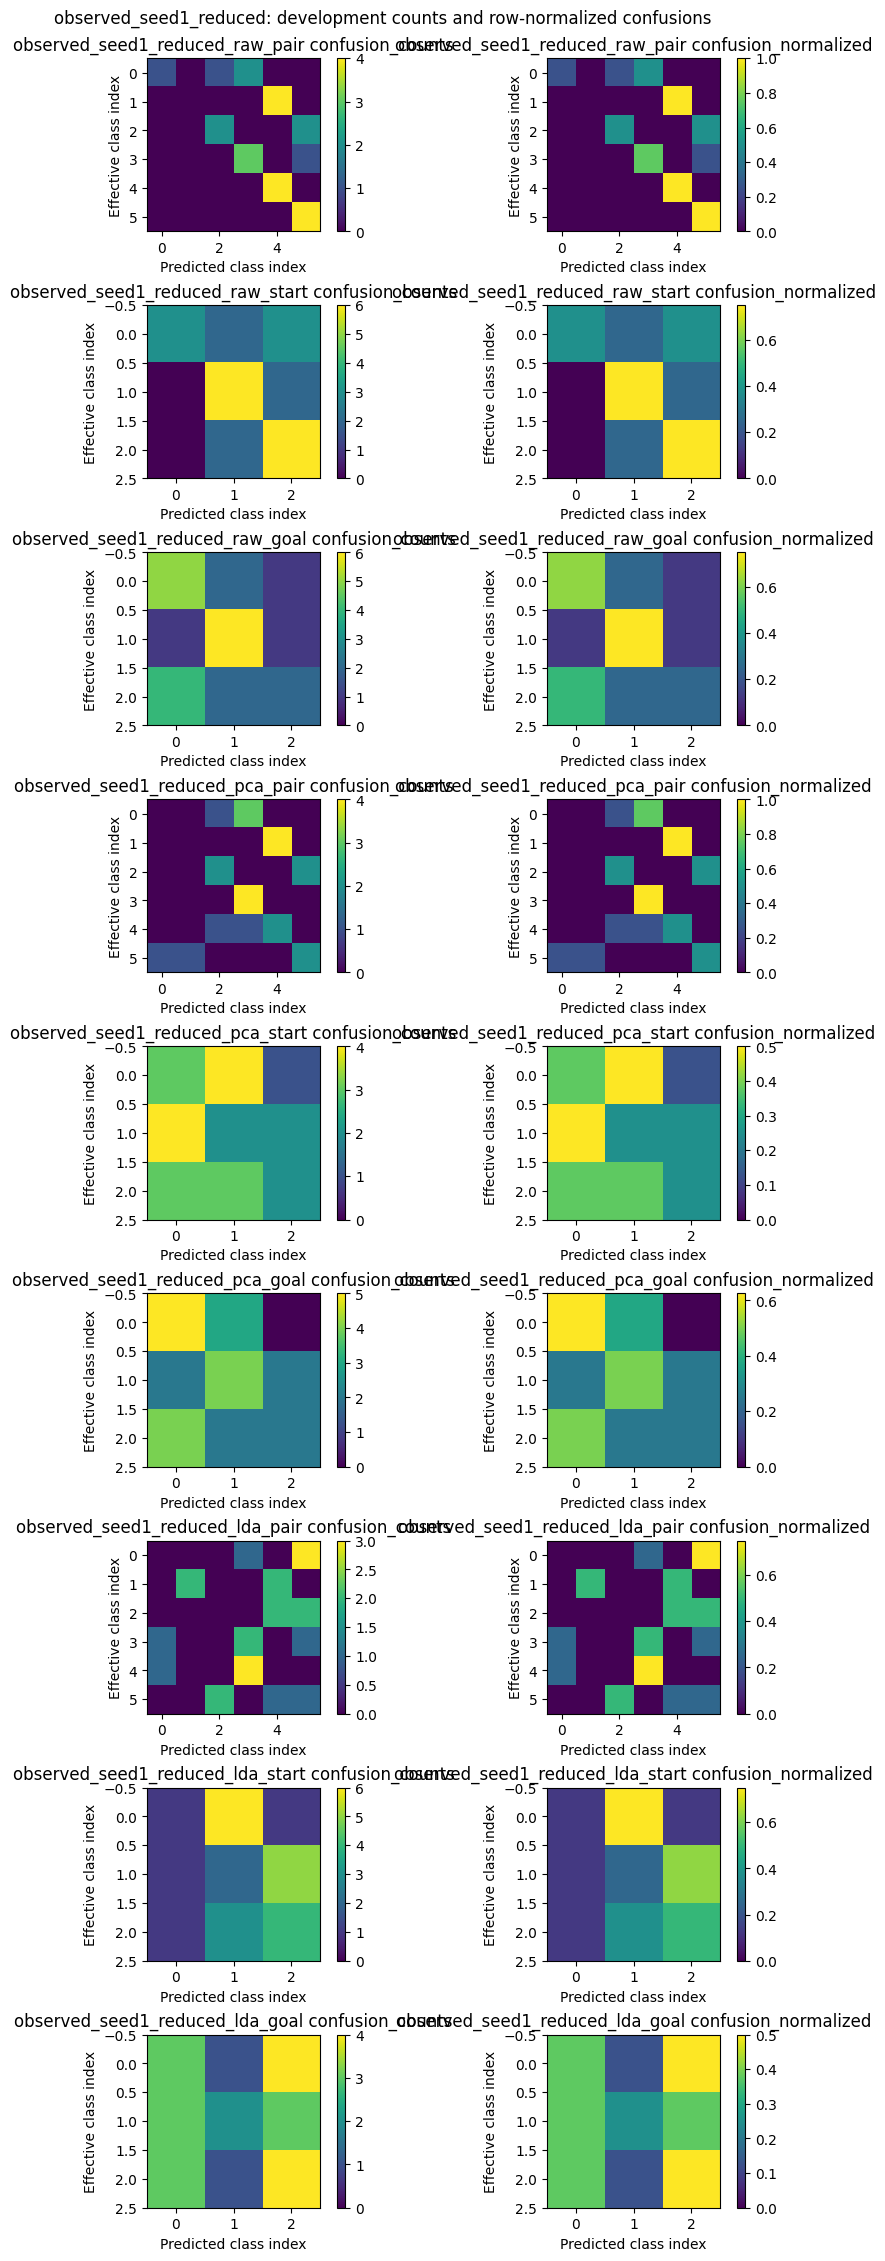

'aggregate_metrics.joblib'

In [5]:
for seed in settings['seeds']:
    for budget in ('full', 'reduced'):
        selected, effective = source_budget(data, observed, reduced=budget == 'reduced', subset_seed=settings['subset_seed'])
        train, development = checked_assemblies(selected, effective, dev_plan, reference_development, config=settings, seed=seed)
        key = f'observed_seed{seed}_{budget}'
        store.save_bundle(key, train, development)
        print(key, 'source accounting:', json.dumps(usage_summary(selected, train), sort_keys=True))
        standardizer = fit_standardizer(train.values)
        raw_train, raw_dev = raw_features(standardizer.transform(train.values)), raw_features(standardizer.transform(development.values))
        pca = fit_pca(train.values, n_components=settings['pca_components'])
        pca_train, pca_dev = pca.transform(train.values), pca.transform(development.values)
        store.save_encoder(key + '_raw', standardizer, kind='raw')
        store.save_encoder(key + '_pca', pca, kind='pca')
        print(key, 'PCA explained variance:', pca.pca.explained_variance_ratio_.round(4).tolist())
        run_results = []
        for representation, train_x, dev_x in (('raw', raw_train, raw_dev), ('pca', pca_train, pca_dev)):
            for head, y in target_heads(train).items():
                model = fit_logistic(train_x, y, C=settings['logistic_C'], max_iter=settings['logistic_max_iter'])
                row = store.readout(key + '_' + representation + '_' + head, model, encoder=key + '_' + representation,
                                    bundle=key, head=head, train_features=train_x, development_features=dev_x)
                run_results.append(row)
        for head, y in target_heads(train).items():
            model = fit_lda(raw_train, y)
            row = store.readout(key + '_lda_' + head, model, encoder=key + '_raw', bundle=key, head=head,
                                train_features=raw_train, development_features=raw_dev)
            run_results.append(row)
        results.extend(run_results)
        print(json.dumps(compact_metrics(run_results), sort_keys=True))
        fig = plot_confusions(run_results, title=key + ': development counts and row-normalized confusions')
        display(fig); plt.close(fig)
store.save('aggregate_metrics', results)

## Training statistics and descriptive projection
The shown projection is not held-out predictive evidence; the numerical held-out scores and confusions above are the assay.

Last training pooled-bin mean/scale: [3.724, 3.427, 3.5, 3.349, 3.74, 3.349, 3.516, 3.484, 3.63] [2.239, 2.014, 2.126, 2.0, 2.304, 2.286, 2.314, 2.087, 2.388]


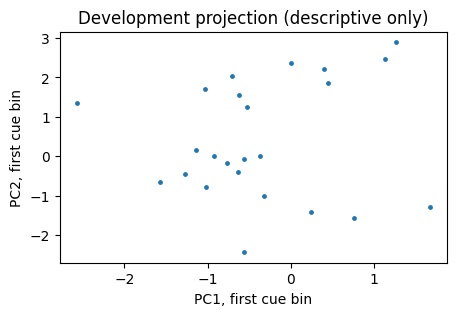

Uniform balanced-accuracy references: {'pair': 0.16666666666666666, 'start': 0.3333333333333333, 'goal': 0.3333333333333333}


In [6]:
print('Last training pooled-bin mean/scale:', standardizer.scaler.mean_.round(3).tolist(), standardizer.scaler.scale_.round(3).tolist())
fig, ax = plt.subplots(figsize=(5, 3)); ax.scatter(pca_dev[:, 0], pca_dev[:, 1], s=6)
ax.set(xlabel='PC1, first cue bin', ylabel='PC2, first cue bin', title='Development projection (descriptive only)')
display(fig); plt.close(fig)
print('Uniform balanced-accuracy references:', {h: 1 / len(np.unique(y)) for h, y in target_heads(development).items()})

## Interpretation limits
These are source-safe conditional pseudopopulations, not simultaneous trials. Matching uses known labels; this is not an unknown-trial prediction pipeline. Bins, synthetic rows and computational seeds are dependent. Place-selected units, provisional marker meaning, inherited preprocessing and historical exposure remain limitations. Contributor separation does not remove long-range serial/session confounds. No biological confidence intervals, p-values, mechanism, dynamics or prospective-path claim follows from these figures. The permutation diagnostic is alignment-breaking, not a biological exchangeability test.

In [7]:
fit_counts = accounting.stop()
store.save('kernel_runtime_final', runtime_identity())
expected_counts = {'pca': 4, 'logistic': 24, 'lda': 12, 'cebra': 0, 'optimizer_updates': 0}
manifest_hash = store.finish(fit_counts=fit_counts, expected_counts=expected_counts)
replay = verify_artifacts(output / 'artifacts', expected_manifest_hash=manifest_hash)
write_private_json(output / 'completion.json', {'manifest_sha256': manifest_hash, 'fit_counts': fit_counts, 'replay': replay})
print(json.dumps(replay, sort_keys=True))
assert replay['status'] == 'fit-blocked-loaded-model-replay-passed'

{"fit_counts": {"cebra": 0, "lda": 12, "logistic": 24, "optimizer_updates": 0, "pca": 4}, "manifest_sha256": "3c8356e7009c935300c599d67f4d423111d6123d76b6b501adf61242ad8ac974", "readout_splits_checked": 72, "status": "fit-blocked-loaded-model-replay-passed"}
